### Visualize Latent Query Features Given Drivving Command by performing tSNE projection.

In [ ]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import os
import torch
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# load data 
def load_features(folder_path):
    data = defaultdict(list)
    for file_name in os.listdir(folder_path):
        if file_name.endswith('.pth'):
            sample_idx = file_name.split('_')[0]
            loaded_data = torch.load(os.path.join(folder_path, file_name))
            data['sample_idx'].append(sample_idx)
            for k, v in loaded_data.items():
                data[k].append(v)
    return data

path = "/home/hao1rng/core/VAD/exps/eval/vad-fixed/probabilistic/slp_egoagent/multivar_normal_mlp/indep_var_mu_baseline/heavy/w1e-1/VAD_tiny_e2e_slp-egoagent_multivar-normal-mlp_indep-var-mu-baseline_heavy_w1e-1_a100_g2_b4_w4_exp_andreas_02-09-2025_10-24-05/VAD_tiny_e2e_slp-egoagent_multivar-normal-mlp_indep-var-mu-baseline_heavy_w1e-1_a100_g2_b4_w4_exp_andreas_02-09-2025_10-24-05_e30_16-09-2025_21-38-46/feats/slp_egoagent_query_prior"
data = load_features(path)
            

In [3]:
data.keys()

dict_keys(['sample_idx', 'ego_fut_cmd_idx', 'ego_agent_query'])

In [5]:
len(data['ego_fut_cmd_idx'])

6019

In [6]:
# stack queries
queries_sublist = [torch.stack(sublist, dim=0) for sublist in data['ego_agent_query']]
queries = torch.stack(queries_sublist, dim=0).squeeze(2)
queries.shape

# stack driving commands
cmds = torch.tensor(data['ego_fut_cmd_idx'])
cmds.shape

torch.Size([6019])

In [35]:
def compute_tSNE(
    features: torch.Tensor,
    n_out_components=2,
    use_pca=True,
    n_pca_components=100,
    perplexity=50,
    learning_rate=200,
    n_iter=1000,
    random_state=42
):
    # Preprocessing pipeline
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(features)

    if use_pca:
        # PCA reduction first
        pca = PCA(n_components=n_pca_components)  # Reduce to 50 dimensions
        X_preprocessed = pca.fit_transform(X_scaled)
    else:
        X_preprocessed = X_scaled

    # t-SNE on reduced data
    tsne = TSNE(
        n_components=n_out_components,
        perplexity=perplexity,
        learning_rate=learning_rate,
        n_iter=n_iter,
        random_state=random_state
    )
    X_tsne = tsne.fit_transform(X_preprocessed)
    return X_tsne

X_tsne = compute_tSNE(queries[:,0], use_pca=False, perplexity=100)
X_tsne.shape

(6019, 2)

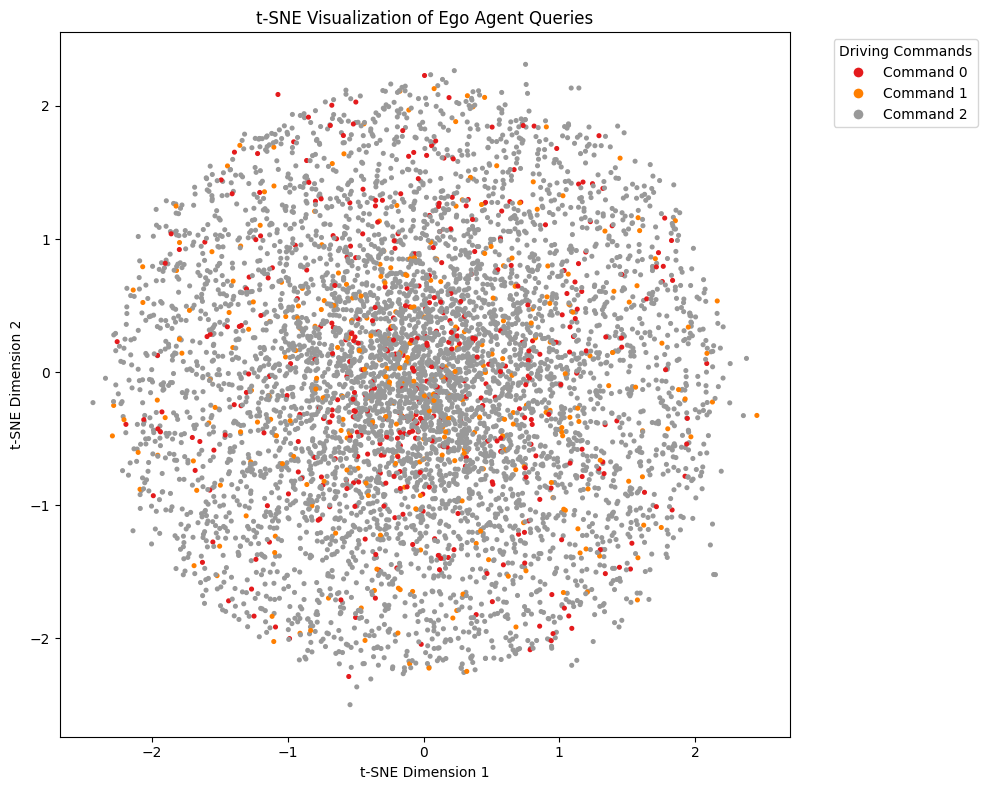

In [36]:
def plot_tsne(X_tsne, save_path=None, color_idxs=None):
    if color_idxs is None:
        color_idxs = np.zeros(X_tsne.shape[0])   
    
    # Get unique color indices that are actually used
    unique_colors = np.unique(color_idxs)
    colormap = plt.cm.get_cmap('Set1', 3)  # 9 distinct colors
    
    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], s=7, alpha=1, c=color_idxs, cmap=colormap)
    plt.title('t-SNE Visualization of Ego Agent Queries')
    plt.xlabel('t-SNE Dimension 1')
    plt.ylabel('t-SNE Dimension 2')
    
    # Create legend handles only for colors that are used
    legend_handles = []
    for color_idx in unique_colors:
        legend_handles.append(plt.Line2D([0], [0], marker='o', color='w', 
                                       markerfacecolor=colormap(color_idx), 
                                       markersize=8, label=f'Command {int(color_idx)}'))
    
    plt.legend(handles=legend_handles, title='Driving Commands', 
              bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
    plt.show()
    
plot_tsne(X_tsne, color_idxs=cmds)
